In [12]:
import pandas as pd

df = pd.read_excel("../data/OLA_DataSet.xlsx", sheet_name="July")
print(df.shape)
df.head()

(103024, 20)


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[us]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  str           
 3   Booking_Status              103024 non-null  str           
 4   Customer_ID                 103024 non-null  str           
 5   Vehicle_Type                103024 non-null  str           
 6   Pickup_Location             103024 non-null  str           
 7   Drop_Location               103024 non-null  str           
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   str           
 11  Canceled_Rides_by_Driver    18434 non-null   str  

In [14]:
df.isna().sum()

Date                              0
Time                              0
Booking_ID                        0
Booking_Status                    0
Customer_ID                       0
Vehicle_Type                      0
Pickup_Location                   0
Drop_Location                     0
V_TAT                         39057
C_TAT                         39057
Canceled_Rides_by_Customer    92525
Canceled_Rides_by_Driver      84590
Incomplete_Rides              39057
Incomplete_Rides_Reason       99098
Booking_Value                     0
Payment_Method                39057
Ride_Distance                     0
Driver_Ratings                39057
Customer_Rating               39057
Vehicle Images                    0
dtype: int64

# Cleaning

In [15]:
# 1. clean column names
df.columns = df.columns.str.strip().str.replace(" ", "_")

# 2. fix data types
df["Date"] = pd.to_datetime(df["Date"]).dt.normalize()
df["Time"] = pd.to_datetime(df["Time"].astype(str), format="%H:%M:%S").dt.time

# 3. fill blanks in text columns with a clear label
fill_cols = ["Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver",
             "Incomplete_Rides", "Incomplete_Rides_Reason", "Payment_Method"]
df[fill_cols] = df[fill_cols].fillna("Not Applicable")

# 4. new columns
dt = pd.to_datetime(df["Date"].astype(str) + " " + df["Time"].astype(str))
df["Hour"] = dt.dt.hour
df["Day_Name"] = dt.dt.day_name()
df["Week"] = dt.dt.isocalendar().week
df["Time_Bucket"] = pd.cut(df["Hour"], [-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"])

print(df.shape)
print(df.isna().sum())
df.head()

(103024, 24)
Date                              0
Time                              0
Booking_ID                        0
Booking_Status                    0
Customer_ID                       0
Vehicle_Type                      0
Pickup_Location                   0
Drop_Location                     0
V_TAT                         39057
C_TAT                         39057
Canceled_Rides_by_Customer        0
Canceled_Rides_by_Driver          0
Incomplete_Rides                  0
Incomplete_Rides_Reason           0
Booking_Value                     0
Payment_Method                    0
Ride_Distance                     0
Driver_Ratings                39057
Customer_Rating               39057
Vehicle_Images                    0
Hour                              0
Day_Name                          0
Week                              0
Time_Bucket                       0
dtype: int64


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,...,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle_Images,Hour,Day_Name,Week,Time_Bucket
0,2024-07-26,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,...,444,Not Applicable,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...,14,Friday,30,Afternoon
1,2024-07-25,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,...,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...,22,Thursday,30,Late Night
2,2024-07-30,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,...,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...,19,Tuesday,31,Evening
3,2024-07-22,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,...,384,Not Applicable,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...,3,Monday,30,Night
4,2024-07-02,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,...,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...,9,Tuesday,27,Morning


In [16]:
df.to_csv("../data/ola_cleaned.csv", index=False)
print("Saved:", df.shape)

Saved: (103024, 24)


# Exploratory Data Analysis (EDA)

## 1. Booking Status Breakdown

**Question:** What share of bookings actually turn into completed rides?

Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64
Booking_Status
Success                 62.1
Canceled by Driver      17.9
Canceled by Customer    10.2
Driver Not Found         9.8
Name: count, dtype: float64


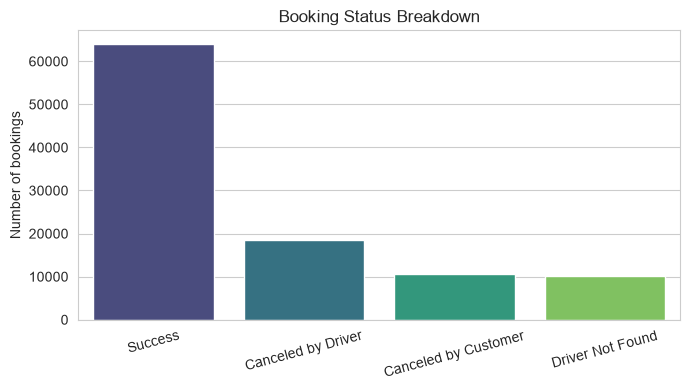

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

status = df["Booking_Status"].value_counts()
print(status)
print((status / len(df) * 100).round(1))

plt.figure(figsize=(7, 4))
sns.barplot(x=status.index, y=status.values, hue=status.index,
            palette="viridis", legend=False)
plt.title("Booking Status Breakdown")
plt.xlabel("")
plt.ylabel("Number of bookings")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Insight:**
- Only about 62% of bookings (63,967) end in a successful ride.
- Roughly 38% never complete: 18% are cancelled by drivers, 10% by customers, and 10% end with no driver found.
- Driver cancellations are almost double customer cancellations, so driver-side issues are the bigger problem to fix.

**Business implication:** Reducing driver cancellations and "Driver Not Found" cases would recover the most lost revenue.

## 2. Ride Volume Over Time

**Question:** How does the number of bookings change day by day through July 2024?

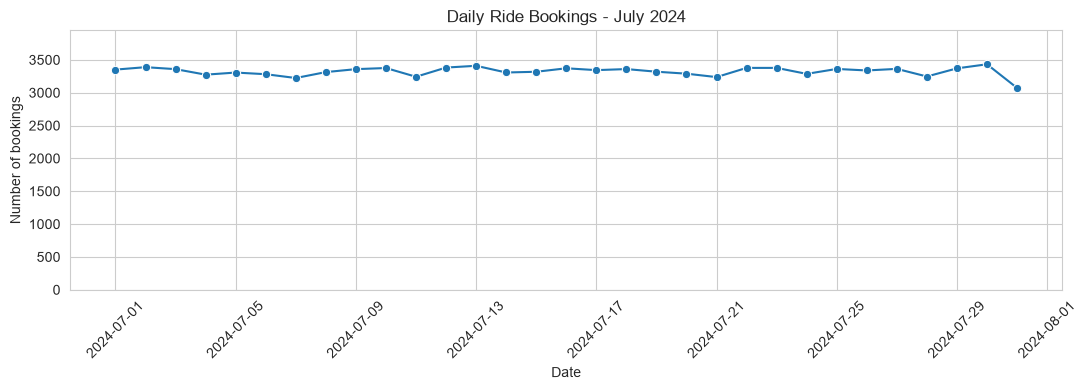

count      31.0
mean     3323.0
std        70.0
min      3072.0
25%      3288.0
50%      3343.0
75%      3370.0
max      3432.0
dtype: float64
Busiest day: 2024-07-30 3432
Quietest day: 2024-07-31 3072


In [18]:
daily = df.groupby("Date").size()

plt.figure(figsize=(11, 4))
sns.lineplot(x=daily.index, y=daily.values, marker="o")
plt.title("Daily Ride Bookings - July 2024")
plt.xlabel("Date")
plt.ylabel("Number of bookings")
plt.xticks(rotation=45)
plt.ylim(0, daily.max() * 1.15)
plt.tight_layout()
plt.show()

print(daily.describe().round(0))
print("Busiest day:", daily.idxmax().date(), daily.max())
print("Quietest day:", daily.idxmin().date(), daily.min())

**Insight:**
- Demand is very stable: bookings average about 3,300 per day, ranging only from 3,072 (31 July) to 3,432 (30 July).
- There is no strong spike or trend across the month, so daily volume alone does not explain the high cancellation rate.
- The more useful angle is *when during the day* demand peaks, which is analysed next.

**Business implication:** Since daily demand is steady, driver supply can be planned on a stable daily baseline. The real optimisation lies in hourly allocation.

## 3. Rides by Hour of Day

**Question:** At which hours is demand highest, so drivers can be allocated accordingly?

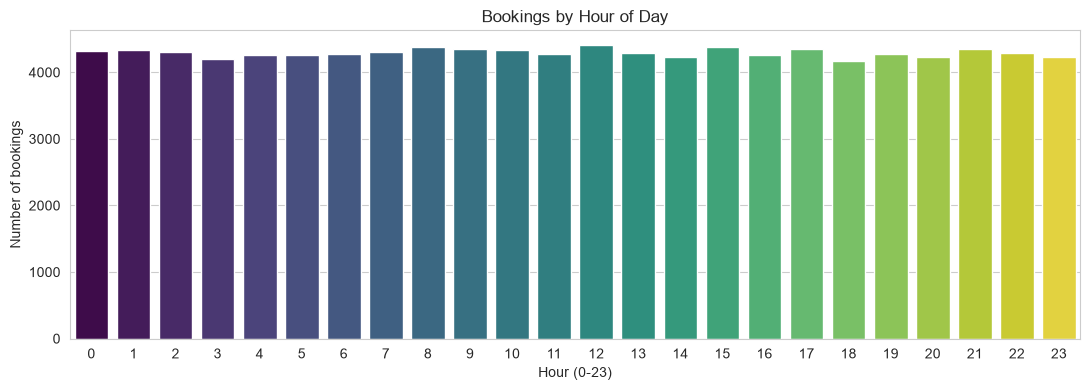

Peak hour: 12 4408
Lowest hour: 18 4176
Hour
12    4408
15    4376
8     4374
17    4353
dtype: int64


In [19]:
hourly = df.groupby("Hour").size()

plt.figure(figsize=(11, 4))
sns.barplot(x=hourly.index, y=hourly.values, hue=hourly.index,
            palette="viridis", legend=False)
plt.title("Bookings by Hour of Day")
plt.xlabel("Hour (0-23)")
plt.ylabel("Number of bookings")
plt.tight_layout()
plt.show()

print("Peak hour:", hourly.idxmax(), hourly.max())
print("Lowest hour:", hourly.idxmin(), hourly.min())
print(hourly.nlargest(4))

**Insight:**
- Demand is almost flat across all 24 hours: every hour has between about 4,180 and 4,410 bookings.
- The highest hour is 12:00 (4,408 bookings) and the lowest is 18:00 (4,176), a gap of only about 5%.
- There is no clear morning or evening rush hour in this dataset.

**Business implication:** There is no single peak window to concentrate drivers on, so driver availability should be spread evenly across the day. Any peak-hour or surge analysis should be treated cautiously, since this data shows no real peaks.